# 08 — The two L2 partitions of the H100 NVL: near and far hits for every SM, line homes, copies and the address hash

**Goal.** The 60 MiB L2 cache of this GPU is split into two partitions, each attached to half of the SMs. An L2 hit therefore costs one of two latencies depending on where the line is held relative to the requesting SM. This experiment answers the questions a placement-aware model of the chip needs:

1. For **every one of the 132 SMs**: which partition is near, what a near hit and a far hit cost, and whether there is finer structure inside a partition (sub-nodes).
2. **Where a line lives.** Is its home decided by the SM that touches it first, or by its address? If by its address, which address bits decide?
3. **Copies.** Does a read from the far side leave a copy in the reader's partition, who can use that copy, and what happens to it when the line is written?
4. **Effective capacity.** How much data can one SM keep in L2 before its accesses turn into far hits and misses?

## Background

**L2 partitions.**
- The L2 is built from 96 slices (the profiler reports 96 `lts` units) grouped into two partitions.
- Each GPC (group of 12–18 SMs) is wired to one partition. An SM reaches the other partition only through a link between the two.
- A line held only in the other partition is therefore a *far hit*: the request and the data cross that link.

**Home and copies.** Two policies are possible:
- *first-touch homing*: a line lives in the partition of the SM that first touched it;
- *address homing*: an address function chooses the partition, as it chooses the slice.

Independently, the partition of a reader may keep a **copy** of a far line, so that later reads are near. A copy raises two questions:
- does it serve only the SM that created it, or every SM of that partition?
- is it invalidated when the line is written?

**Why only the first read can be far.** If reads leave copies, a pointer chase that revisits its lines sees far hits only on the very first visit of each line by a partition. Measuring far hits therefore requires full control of the cache state:
1. remove the line from the L2;
2. let a chosen SM touch it;
3. time the first read from the probe SM.

**Address bits.**
- Memory is allocated in 2 MiB pages, so bits 0–20 of an address are the same in the virtual and the physical address. Higher bits are chosen by the driver's page mapping.
- A hash that selects one of two partitions is typically the parity (XOR) of a set of address bits. Flipping one bit of the set changes the partition; flipping a bit outside it never does; flipping two bits of the set changes nothing.
- If the hash is linear in this sense, single-bit flips predict every multi-bit flip.

**Per-access timing.** One thread reads `%clock64`, issues a load, and reads `%clock64` again once the loaded value is available. The second read is made to depend on the loaded value:
```
t0 = %clock64;  p = ld.global.cg.u64 [p];  t1 = %clock64 (issued after p arrived)
```
The difference includes the cost of the timer pair itself, which is measured separately and subtracted. Each line stores its own address in its first 8 bytes, so `p = *p` re-reads the same line with every load depending on the previous one.

## Experimental setup

**Device and configuration.**
- NVIDIA H100 NVL: 132 SMs in 8 GPCs, 60 MiB L2, HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off.
- Driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`).
- SM clock locked at 1635 MHz with `nvidia-smi -lgc`. Each configuration is followed by an NVML sample of clocks and throttle reasons (table below).
- GPC numbering G0–G7 and the SM → GPC map come from an earlier cluster-placement experiment on the same card.

**Common protocol (every configuration).**
1. **Empty the L2.** Read-modify-write a 128 MB buffer, then read another 128 MB buffer, so that no line of the test buffer is cached and no dirty line is being written back during the measurement.
2. **Touch.** A single warp pinned to a chosen SM writes each test line completely: 128 bytes, the first 8 being the line's own address. This is the line's first touch.
3. **Probe.** One block per SM is launched with 200 KB of shared memory each, so every SM holds exactly one block; only the block on the probe SM works. One thread visits the lines one after another. For each line it:
   - first reads, untimed, a reserved line of the same 2 MiB page, so that the first timed read does not pay an address-translation miss;
   - then times 64 dependent reads of the line (sample 0 = the probe SM's first read of the line).

   Samples are kept in shared memory and copied out between lines, outside the timed pairs.

Pinning works by `%smid`: each block reads its SM id and only the one on the target SM proceeds; the host checks and re-launches if needed.

**Naming.** The partition containing SM 0 (GPC 0) is called partition 0, the one containing SM 2 (GPC 1) partition 1. A *labelling pass* gives each test line its home:
1. SM 0 writes the candidate lines;
2. SM 2 reads each line once;
3. a far first read means the line is homed in partition 0, a near one in partition 1.

**Kernels.**
- **K1, one line, 64 reads.**
  - Probes SM 0 and SM 2; 32 lines (16 homed in each partition).
  - Toucher: the probe itself, or the SM of the other partition.
  - With or without one untimed warm-up read; `ld.global.cg` (L2 only) and `ld.global.ca` (L1 allowed).
  - 5 launches per configuration.
- **K5, every SM.**
  - 256 lines of an 8 MiB buffer: 128 homed in each partition, each written by an SM of its home partition, so every line exists only at home.
  - For each of the 132 SMs and 5 repetitions: empty the L2, touch, then the SM reads every line 64 times.
  - The first read gives near and far latencies per SM; reads 2–64 give the latency of whatever copy the first read left.
- **K2, address bits.**
  - A 2 GiB buffer. Line sets:
    - 32 random base lines L and, for every bit b from 7 to 30, the line L ⊕ 2^b;
    - every pair of bits 7–20 flipped together, plus 32 random multi-bit masks of bits 7–20 per base;
    - 4 fixed in-page offsets in all 1024 pages.
  - All lines are written by one reference SM and first-read by the reference SM of the other partition, in a random order, in both directions, 3 repetitions. A line's home is the class (near or far) of its first read.
- **K2 on explicitly mapped physical memory.** The driver API allocates physical memory (`cuMemCreate`, 2 MiB granularity) and maps it at chosen virtual addresses (`cuMemMap`), so one physical page can be probed at several virtual addresses.
  - 64 separate 2 MiB allocations ("handles"), each mapped three times into 128 MiB-aligned virtual ranges: A1 puts handle k at slot k; A2 puts handle k at slot k ⊕ 0b01011, i.e. at a virtual address that differs in bits 21, 22 and 24; A3 uses a random permutation.
  - Four 32 MiB and two 64 MiB allocations, each mapped once at a virtual address aligned to its size, and one 256 MiB `cudaMalloc` buffer.
  - 8 fixed in-page lines per 2 MiB page. Per mapping, direction and repetition (2 × 3): empty the L2, one reference SM writes every line, the other reads each line 8 times; the first read gives the home.
- **K3, copies.**
  - Three SMs: A; B in the other partition; C in B's partition but another GPC. Three such triples plus one control triple with all three SMs in one partition.
  - 32 lines (16 homed with A, 16 with B).
  - Sequence:
    1. empty the L2, A writes the lines;
    2. B reads (64 times each);
    3. C reads;
    4. A reads;
    5. A rewrites the lines with a new value;
    6. B reads again, and checks that it sees the new value.
  - Each step is either its own kernel launch, or all steps run in one launch ordered by release/acquire flags in global memory. 5 repetitions.
- **K4, effective capacity.**
  - A random cyclic pointer chain over one 128-byte line after another, footprints 16–80 MiB in 2 MiB steps.
  - Touched by the probe SM itself, or alternately by SM 0 and SM 2 (even/odd lines).
  - The probe (SM 0 or SM 2) then chases the whole chain three times, timing every hop into an on-chip histogram (exact counts per cycle value), and a fourth time untimed. 3 repetitions.
- **Hardware counters.** Nsight Compute in application-replay mode (every counter pass re-runs the whole protocol), with the clock lock kept:
  - one line × 64 reads per profiled kernel, and the K4 chase after two warm passes: all counters in one profile, 4 counter passes;
  - first reads of 65 k far-homed or near-homed lines: every profiled kernel alone in its own run of the binary, with a single L2 counter (one counter pass), plus a baseline kernel with the same grid in which every block exits at once.

In [1]:
%matplotlib inline
import os
import re
import sys
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from common08 import runs, latest_run, read_run, kmeans1d, timer_pair
from analysis08 import (gpc_map, load_k5, sm_signature, line_groups, share_null, k2_bits, k2_linearity, quad_table,
                        k2_first_reads, k2_page_terms, k2vmm, gmm1d, fabric1)

QUICK = os.environ.get("NB08_QUICK") == "1"
R, EXP = "results", "08__l2_partitions_and_first_touch"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#a35bd0", "#d4a20c", "#d6457a", "#4fb3c8", "#7a6e5c"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 1)

reg = runs()
RID = {m: latest_run(t, m, QUICK) for t, m in [("l2_probe", "calib"), ("l2_probe", "k1"), ("l2_probe", "k2"), ("l2_probe", "k2vmm"),
                                              ("l2_probe", "k3"), ("l2_probe", "k5"), ("l2_capacity", "k4")]}
GPC = gpc_map()
TP = timer_pair(quick=QUICK)
def last_tag(f):
    d = pd.read_csv(f"{R}/{f}")
    return d[d.run_id == d.run_id.max()]
NCU = {t: last_tag(f"08__l2__ncu_{t}.csv") for t in ("lines", "fabric", "capacity")}
# Multi-pass profiles (one line, capacity; and the superseded fabric profile): under application replay the binary runs once per
# counter pass, and the first pass ran the profiled kernels 2.6–2.8× slower (section 6), so their cycle counts are taken as the
# median over the other passes' manifests.
_man = pd.read_csv(f"{R}/08__l2__ncu_manifest.csv")
for t, mode in [("lines", "ncu_lines"), ("fabric", "ncu_fabric"), ("capacity", "ncu_capacity")]:
    r0, nb = NCU[t].run_id.iloc[0], int(NCU[t].binary_runs.iloc[0])
    rs = sorted(_man[(_man["mode"] == mode) & (_man.run_id >= r0)].run_id.unique())[:nb]
    mm = _man[_man.run_id.isin(rs)]
    NCU[t]["first_median_pass1"] = NCU[t].first_median
    NCU[t]["first_median"] = NCU[t].ncu_order.map(mm[mm.run_id != rs[0]].groupby("ncu_order").first_median.median())
    NCU[t]["pass_runs"] = len(rs)
MHZ = float(NCU["capacity"]["sm__cycles_elapsed.avg.per_second"].median() / 1e6)
clog = pd.read_csv(f"{R}/{EXP}__clock_log.csv")
stats = pd.read_csv(f"{R}/08__l2__launch_stats.csv")
print("runs used:", RID)

runs used: {'calib': '2026-10-24T21:42:05.209+00:00', 'k1': '2026-10-24T21:42:05.870+00:00', 'k2': '2026-10-24T21:42:07.555+00:00', 'k2vmm': '2026-10-25T01:36:09.406+00:00', 'k3': '2026-10-25T01:36:10.640+00:00', 'k5': '2026-10-24T21:42:13.213+00:00', 'k4': '2026-10-24T21:42:20.004+00:00'}


In [2]:
L = clog[(clog.phase == "launch") & clog.run_id.isin(RID.values())]
first = L.iloc[0]
display(pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all configurations)": [f"{L.sm_clock_mhz.min()}–{L.sm_clock_mhz.max()} MHz"],
    "SM clock measured by the profiler (median)": [f"{MHZ:.0f} MHz"],
    "memory clock (NVML)": [f"{L.mem_clock_mhz.min()}–{L.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{L.power_w.min():.0f}–{L.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{L.gpu_temp_c.max()} / {L.mem_temp_c.max()} °C"],
}).T.rename(columns={0: ""}))
used = reg[reg.run_id.isin(RID.values())].assign(mode=lambda r: r.cmdline.str.split().str[:2].str.join(" "))
st = stats[stats.run_id.isin(RID.values())].groupby("run_id")[["configs", "claim_retries", "bad_clock_configs"]].sum()
used = used.join(st, on="run_id")
display(used[["run_id", "mode", "complete", "configs", "claim_retries", "bad_clock_configs"]]
        .rename(columns={"configs": "recorded configurations", "claim_retries": "re-launches (no block on the target SM / flag timeout)",
                         "bad_clock_configs": "configurations with a clock warning"}).reset_index(drop=True))
cal = read_run("08__l2__probe.csv", RID["calib"])
print(f"timer calibration: per-access-timed ld.shared median {cal.cycles.median():.0f} cycles (p5–p95 {cal.cycles.quantile(.05):.0f}–"
      f"{cal.cycles.quantile(.95):.0f}) over {len(cal)} samples on SMs {sorted(cal.probe_smid.unique())}; "
      f"ld.shared latency 23 cycles → timer pair {TP:.0f} cycles, subtracted from every latency below")
sass = open("results/sass/l2_probe.sass").read().split("Function : ")
blk = [b for b in sass if b.startswith("_Z7k_probeILi0EE")][0].splitlines()
ins = [l.split(";")[0].split("*/")[-1].strip() for l in blk if re.search(r"/\*[0-9a-f]{4}\*/", l)]
i = max(j for j, l in enumerate(ins) if l.startswith("CS2R") and "CLOCK" in l and ins[j + 1].startswith("LDG"))
print("\nSASS of the timed sample (k_probe, ld.global.cg):\n  " + "\n  ".join(ins[i:i + 4]))

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all configurations),1635–1635 MHz
SM clock measured by the profiler (median),1631 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),87–92 W
GPU / HBM temperature max,32 / 36 °C


,run_id,mode,complete,recorded configurations,re-launches (no block on the target SM / flag timeout),configurations with a clock warning
0,2026-10-24T21:42:05.209+00:00,bin/l2_probe calib,True,6,0,0
1,2026-10-24T21:42:05.870+00:00,bin/l2_probe k1,True,81,0,0
2,2026-10-24T21:42:07.555+00:00,bin/l2_probe k2,True,6,0,0
3,2026-10-24T21:42:13.213+00:00,bin/l2_probe k5,True,661,0,0
4,2026-10-24T21:42:20.004+00:00,bin/l2_capacity k4,True,396,0,0
5,2026-10-25T01:36:09.406+00:00,bin/l2_probe k2vmm,True,60,0,0
6,2026-10-25T01:36:10.640+00:00,bin/l2_probe k3,True,41,0,0


timer calibration: per-access-timed ld.shared median 26 cycles (p5–p95 26–26) over 24576 samples on SMs [np.int64(0), np.int64(2)]; ld.shared latency 23 cycles → timer pair 3 cycles, subtracted from every latency below

SASS of the timed sample (k_probe, ld.global.cg):
  CS2R R8, SR_CLOCKLO
  LDG.E.64.STRONG.GPU R4, desc[UR6][R4.64]
  LOP3.LUT R13, R4, UR8, RZ, 0xc0, !PT
  CS2R R10, SR_CLOCKLO


## Results

### 1. One line, 64 reads (K1)

**Figure 1 — one line read 64 times in a row.** For each line the probe SM's 64 dependent reads are timed individually: median over the 16 lines of each kind and 5 launches, p5–p95 shaded. Two variables:
- who wrote the line after the L2 was emptied: the probe itself, or the reference SM of the other partition;
- where the line's home is relative to the probe ("home near" / "home far", from the labelling pass).

Left: `ld.global.cg`. Right: `ld.global.ca`, which may cache the line in the SM's L1.

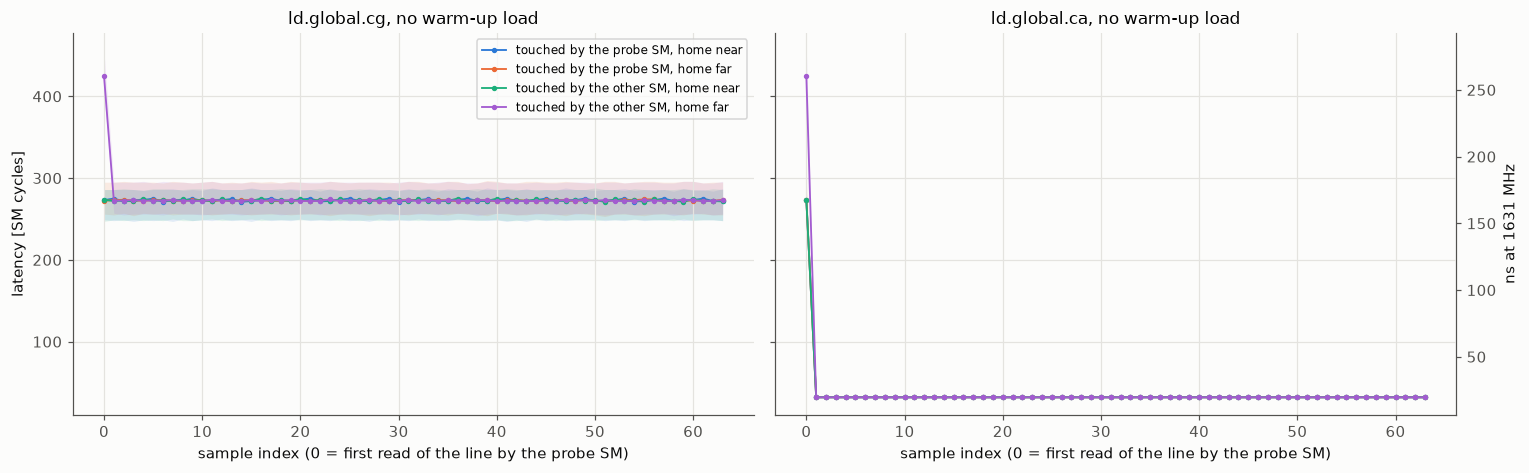

In [3]:
k1 = read_run("08__l2__probe.csv", RID["k1"])
k1 = k1[k1.kernel == "K1"].copy()
k1["cyc"] = k1.cycles - TP
part_of = {0: 0, 2: 1}  # partitions are named after SM 0 (label 0) and SM 2 (label 1)
k1["home"] = np.where(k1.line_home == k1.probe_smid.map(part_of), "home near", "home far")
k1["touch"] = np.where(k1.first_touch_smid == k1.probe_smid, "touched by the probe SM", "touched by the other SM")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, v in zip(axs, ["cg", "ca"]):
    for c, (t, h) in zip(PAL, [(t, h) for t in ["touched by the probe SM", "touched by the other SM"] for h in ["home near", "home far"]]):
        d = k1[(k1.load_variant == v) & (k1.warm == 0) & (k1.touch == t) & (k1.home == h)]
        g = d.groupby("sample_idx").cyc
        ax.plot(g.median().index, g.median(), "-o", ms=2.5, lw=1.2, color=c, label=f"{t}, {h}")
        ax.fill_between(g.median().index, g.quantile(.05), g.quantile(.95), color=c, alpha=0.12, lw=0)
    ax.set_title(f"ld.global.{v}, no warm-up load"); ax.set_xlabel("sample index (0 = first read of the line by the probe SM)")
axs[0].set_ylabel("latency [SM cycles]"); axs[0].legend(fontsize=8)
sec = axs[1].secondary_yaxis("right", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_ylabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()
k1["sample"] = np.where(k1.sample_idx == 0, "sample 0", "samples 1–63")
t = k1.groupby(["load_variant", "warm", "touch", "home", "sample"]).cyc.median().unstack("sample")
display(t.round(0).style.format("{:.0f}").set_caption("median cycles (timer pair removed); probes SM 0 and SM 2, 32 lines, all launches"))

- **Only one case is ever far:** a line homed in the other partition *and* written by an SM of that other partition. Then the probe's first read costs ≈ 425 cycles and every later read ≈ 273.
- **Writing a line also leaves a copy.** When the probe itself wrote a far-homed line, its first read is already near (272): the write left a copy in the writer's partition.
- **One untimed warm-up read gives the same result:** every timed read is then near. A single read therefore suffices to create the copy.
- **`.ca` against `.cg`.** With `.ca`, reads 2–64 cost 32 cycles: they are L1 hits, and the profiler counts 63 L1 hits per line (section 6). With `.cg` they stay at ≈ 273 with no L1 hit, so every `.cg` number in this notebook is an L2 latency.

### 2. Every SM (K5)

Every SM read 256 lines, each held only in its home partition: 128 homed in partition 0, 128 in partition 1. The first read of each line is near or far depending on the reading SM's partition; reads 2–64 hit whatever copy the first read left. All per-SM values are medians over 5 repetitions.

**Figure 2 — every SM.**
- Rows are GPCs, ordered by partition and sub-node (labels derived below); cells are SMs, labelled with their SM id.
- (a), (b): first reads of lines homed in the SM's own partition, split by the sub-node group of the line.
- (d), (e): the same for lines homed in the other partition.
- (c), (f): the differences.

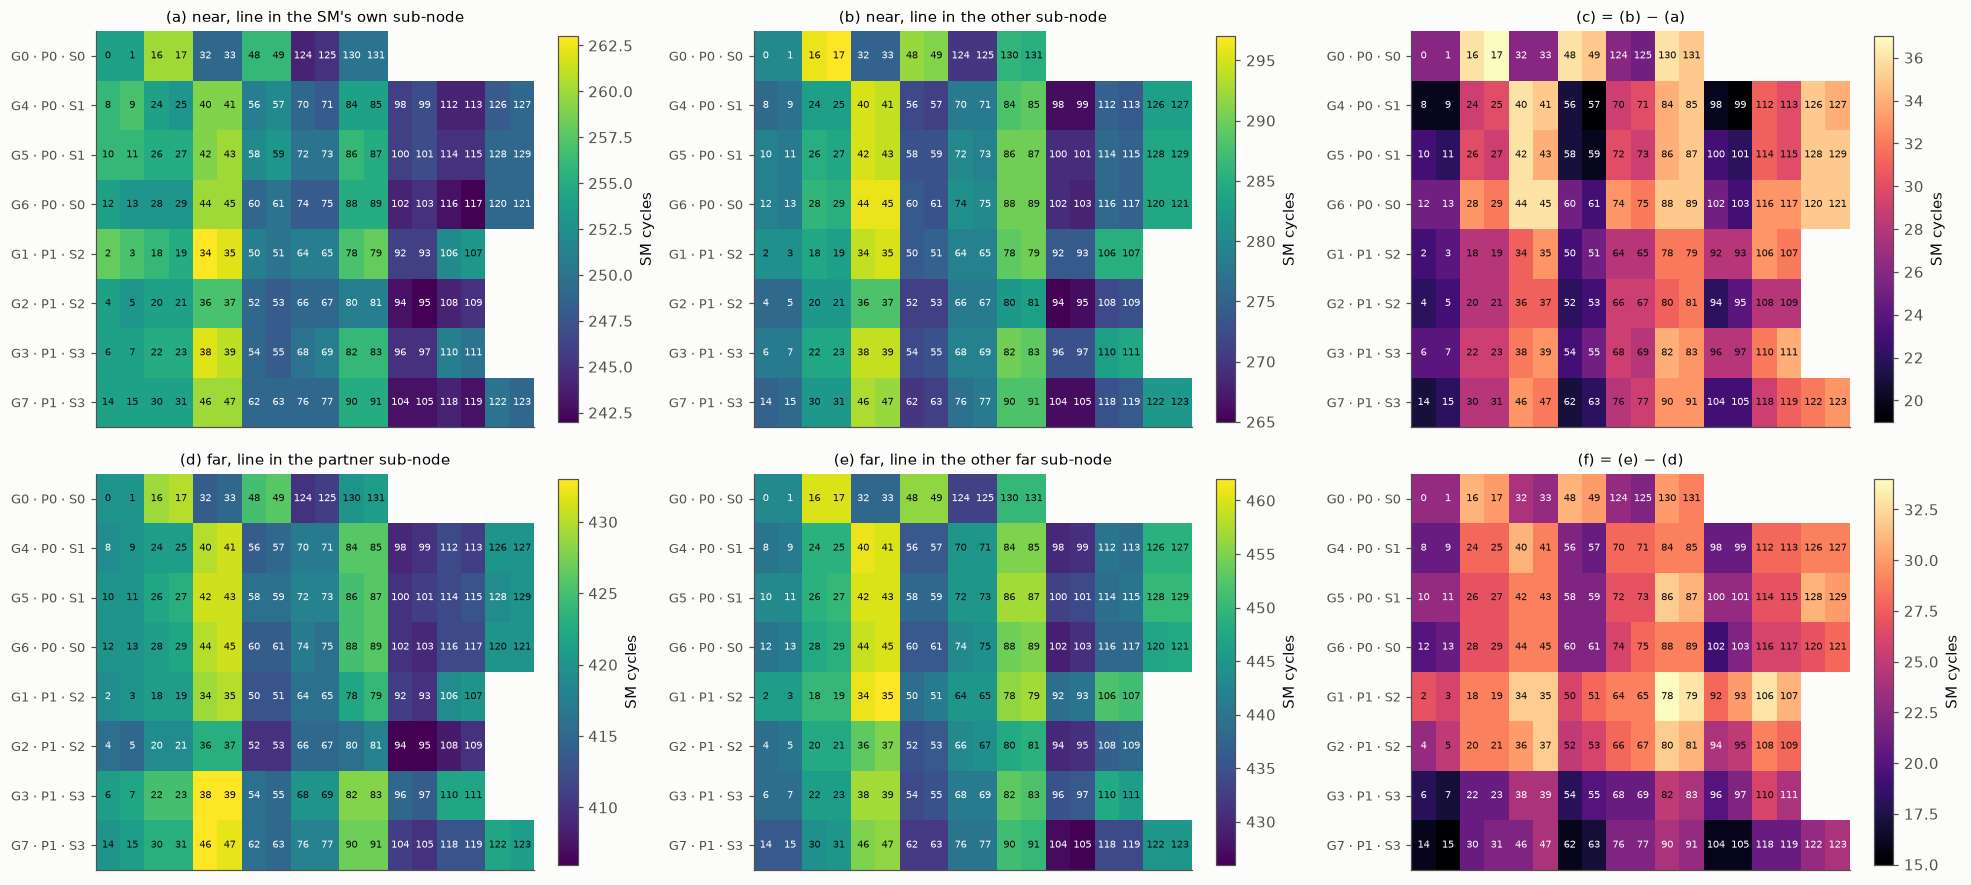

In [4]:
k5, seq = load_k5(RID["k5"], samples=True)
sig, groups = sm_signature(k5, TP)
order = sig.sort_values(["partition", "gpc", "smid"])
gpcs = [g for p in (0, 1) for g in sorted(order[order.partition == p].gpc.unique())]
W = int(sig.groupby("gpc").size().max())
sig["far_axis_offset"] = sig.far_hi_median - sig.far_lo_median
PANELS = [("near_same_subnode_median", "(a) near, line in the SM's own sub-node"), ("near_other_subnode_median", "(b) near, line in the other sub-node"),
          ("subnode_offset", "(c) = (b) − (a)"), ("far_lo_median", "(d) far, line in the partner sub-node"),
          ("far_hi_median", "(e) far, line in the other far sub-node"), ("far_axis_offset", "(f) = (e) − (d)")]
fig, axs = plt.subplots(2, 3, figsize=(18, 8.2))
for ax, (col, title) in zip(axs.ravel(), PANELS):
    A = np.full((len(gpcs), W), np.nan)
    for i, g in enumerate(gpcs):
        sv = sig[sig.gpc == g].sort_values("smid")
        A[i, :len(sv)] = sv[col].values
    im = ax.imshow(A, cmap="magma" if "offset" in col else "viridis", aspect="auto")
    mid = np.nanmean([np.nanmin(A), np.nanmax(A)])
    for i, g in enumerate(gpcs):
        sv = sig[sig.gpc == g].sort_values("smid")
        for j, (sm, v) in enumerate(zip(sv.smid, sv[col])):
            ax.text(j, i, f"{sm}", ha="center", va="center", fontsize=6.5, color="white" if v < mid else INK)
    ax.set_yticks(range(len(gpcs)), [f"G{g} · P{int(sig[sig.gpc == g].partition.iloc[0])} · S{int(sig[sig.gpc == g].subnode.iloc[0])}" for g in gpcs], fontsize=8.5)
    ax.set_xticks([]); ax.grid(False); ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.04, label="SM cycles")
fig.tight_layout(); plt.show()

- **Every SM has one partition.** All 132 SMs read one half of the lines at 242–263 (own sub-node) or 265–297 cycles (other sub-node), and the other half at 406–462 cycles (per-SM medians). The half that is fast is the same for all SMs of a GPC: **partition 0 = {G0, G4, G5, G6} and partition 1 = {G1, G2, G3, G7}**, 66 SMs each.
- **Sub-nodes.** Each partition contains two sub-nodes of two GPCs each: S0 = {G0, G6} and S1 = {G4, G5} in partition 0; S2 = {G1, G2} and S3 = {G3, G7} in partition 1. They are found without assumptions:
  1. Take the SM × line matrix of near first reads.
  2. Its first principal component splits both the SMs and the lines into two groups.
  3. The SM groups are exactly these GPC pairs, with no SM in a mixed group.
- **A per-SM term inside every GPC.** Within one sub-node, latency still varies by ≈ 18 cycles: −8 to +10 around the GPC median, same lines. It varies the same way in all four panels:
  - the two SMs of a TPC (2t, 2t+1) agree within 1 cycle;
  - in G1–G7 the third TPC in SM-id order (SMs 34–47) is the slowest, in G0 the second (SMs 16, 17);
  - the seventh and eighth TPCs (SMs 92–119) are the fastest.

  This is a property of where the SM sits, not of the line.
- **The sub-node offset varies by SM** (19–37 cycles in (c), 15–34 in (f)) and again follows the TPC.

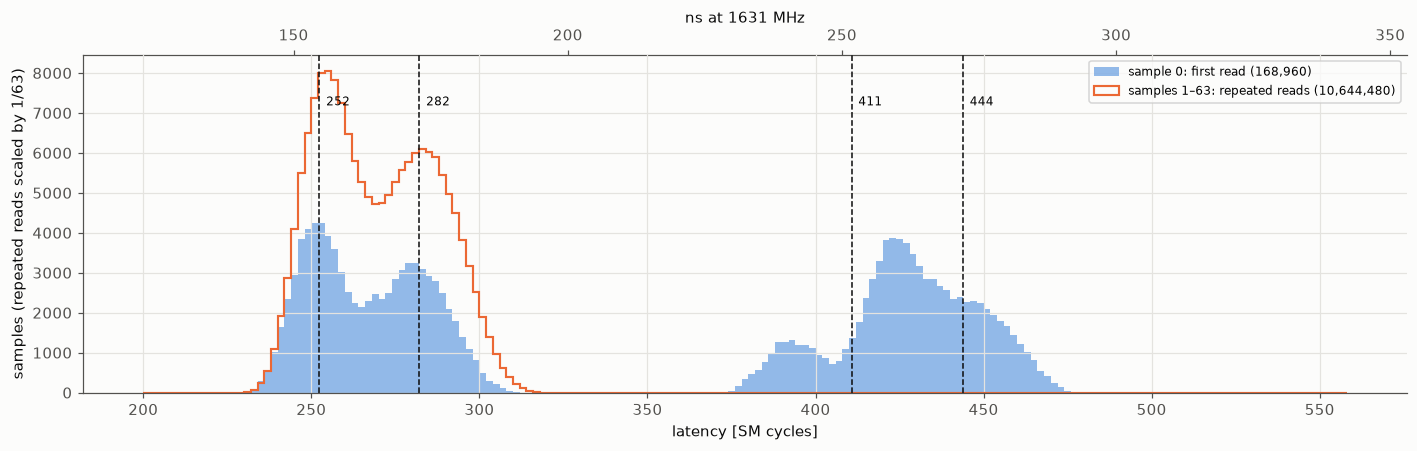

,centre,SD,CV %,share %
"near, own sub-node",252.4,7.7,3.1,26.7
"near, other sub-node",282.2,8.7,3.1,23.3
"far, low",410.7,13.8,3.4,24.9
"far, high",443.9,11.1,2.5,25.1


samples above 560 cycles (not drawn): first reads 0, repeated reads 0 of 10,644,480


In [5]:
first = (k5.first_cycles - TP).values
rep = (seq[:, 1:].ravel() - TP)
cen, lab, sd, wt = kmeans1d(*np.unique(first, return_counts=True), k=4)
fig, ax = plt.subplots(figsize=(13, 4.2))
bins = np.arange(200, 560, 2)
ax.hist(first, bins=bins, histtype="stepfilled", color=PAL[0], alpha=0.5, label=f"sample 0: first read ({len(first):,})")
ax.hist(rep, bins=bins, histtype="step", color=PAL[1], lw=1.4, label=f"samples 1–63: repeated reads ({len(rep):,})", weights=np.full(len(rep), 1 / 63))
for c in cen:
    ax.axvline(c, color=INK, ls="--", lw=1); ax.text(c + 2, ax.get_ylim()[1] * 0.85, f"{c:.0f}", fontsize=8)
ax.set_xlabel("latency [SM cycles]"); ax.set_ylabel("samples (repeated reads scaled by 1/63)"); ax.legend(fontsize=8)
sec = ax.secondary_xaxis("top", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_xlabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()
display(pd.DataFrame({"centre": cen, "SD": sd, "CV %": 100 * sd / cen, "share %": 100 * wt / wt.sum()},
                     index=["near, own sub-node", "near, other sub-node", "far, low", "far, high"]).round(1)
        .style.format("{:.1f}").set_caption("4-means classes of all first reads (timer pair removed)"))
print(f"samples above 560 cycles (not drawn): first reads {(first > 560).sum()}, repeated reads {(rep > 560).sum()} of {len(rep):,}")

In [6]:
quad, partner = quad_table(k5, sig, groups, TP)
tq = quad.groupby(["partition", "position"]).c.agg(median="median", p5=lambda x: x.quantile(.05), p95=lambda x: x.quantile(.95), mean="mean", n="size")
display(tq.round(1).style.format(precision=1).set_caption("first reads by placement of the line relative to the reading SM (cycles, timer pair removed)"))
names_ = {0: "S0 {G0,G6}", 1: "S1 {G4,G5}", 2: "S2 {G1,G2}", 3: "S3 {G3,G7}"}
names_ = {k: v for k, v in names_.items()}
sub_g = sig.groupby("subnode").gpc.agg(lambda x: "{" + ",".join(f"G{g}" for g in sorted(set(x))) + "}")
print("partner sub-nodes (the far sub-node each sub-node reads fastest): "
      + ", ".join(f"S{a} {sub_g[a]} → S{b} {sub_g[b]}" for a, b in sorted(partner.items())))
m = tq["mean"]
print(f"additive check: same/same {m.iloc[3]:.1f} + sub-node step {m.iloc[2]-m.iloc[3]:.1f} + partition step {m.iloc[1]-m.iloc[3]:.1f} "
      f"= {m.iloc[2]+m.iloc[1]-m.iloc[3]:.1f} vs measured other/other {m.iloc[0]:.1f} (means)")

partner sub-nodes (the far sub-node each sub-node reads fastest): S0 {G0,G6} → S3 {G3,G7}, S1 {G4,G5} → S2 {G1,G2}, S2 {G1,G2} → S1 {G4,G5}, S3 {G3,G7} → S0 {G0,G6}
additive check: same/same 251.6 + sub-node step 29.0 + partition step 161.5 = 442.2 vs measured other/other 441.8 (means)


**Figure 3 — all samples.**
- The first reads (blue) form four groups: near hits in the own and the other sub-node, and far hits in two groups.
- Reads 2–64 (orange) contain only the two near groups: after its first read, no line is ever far again.
- A small third far group near 390 cycles holds ≈ 12 % of the far first reads. It occurs only for lines in the partner sub-node (table below), for some lines and some SMs of a sub-node: a finer structure than sub-nodes, which this experiment does not resolve.

**The 2 × 2 structure (table above).**
- The far sub-node an SM reads fastest is always the same one: S0 ↔ S3 and S1 ↔ S2 are partners across the partition boundary.
- With that pairing, every first read falls into one of four cells. The two costs simply add (means): other sub-node position +29.0 cycles, other partition +161.5. Both together are predicted at 442.2 cycles and measured at 441.8.
- The L2 therefore behaves like a 2 × 2 grid of quadrants: {G0, G6} | {G3, G7} on one row and {G4, G5} | {G1, G2} on the other. Crossing between the partitions costs ≈ 162 cycles, crossing between the two rows ≈ 29.

In [7]:
agg = sig.groupby("gpc").agg(SMs=("smid", "size"), partition=("partition", lambda x: "/".join(map(str, sorted(set(x))))),
                             subnode=("subnode", lambda x: "/".join(map(str, sorted(set(x))))),
                             near=("near_median", "median"), near_own_subnode=("near_same_subnode_median", "median"),
                             near_other_subnode=("near_other_subnode_median", "median"), subnode_offset=("subnode_offset", "median"),
                             far=("far_median", "median"), far_low=("far_lo_median", "median"), far_high=("far_hi_median", "median"),
                             copy=("copy_median", "median"), home_repeat=("home_repeat_median", "median"))
agg = agg.loc[gpcs]
display(agg.rename(index=lambda g: f"G{g}").round(1).style.format(precision=1)
        .set_caption("per GPC: medians over its SMs of each SM's median (cycles, timer pair removed)"))
spread = sig.groupby("partition")[["near_median", "far_median", "near_same_subnode_median", "near_other_subnode_median", "copy_median"]].agg(["min", "max"])
display(spread.round(1).style.format(precision=1).set_caption("range of the per-SM medians within each partition"))
odd = sig[sig.smid >= 124].set_index("smid")[["gpc", "partition", "subnode", "near_same_subnode_median", "near_other_subnode_median", "far_median", "copy_median"]]
display(odd.round(1).style.format(precision=1).set_caption("SMs 124–131"))
for p in (0, 1):
    g = groups[p]
    other = groups[1 - p]["line"]
    fl, cl = g["far_line"], g["copy_line"]
    common = fl.index.intersection(other.index)
    a_far = (fl[common] == other[common]).mean(); a_copy = (cl[common] == other[common]).mean()
    print(f"partition {p}: first component explains {100*g['ev']:.0f} % of the centred near matrix "
          f"({100*g['far_ev']:.0f} % far, {100*g['copy_ev']:.0f} % repeated reads of far lines); "
          f"line groups of far first reads vs the lines' sub-node groups at home: {100*max(a_far, 1-a_far):.0f} % agree; "
          f"line groups of the copies vs home sub-node groups: {100*max(a_copy, 1-a_copy):.0f} % agree")
# Is the first-component share larger than for a matrix without SM × line structure? 1000 permutations (seed 0) per matrix.
dd = k5.assign(lat_first=k5.first_cycles - TP, lat_repeat=k5.repeat_median - TP)
nrows = []
for p in (0, 1):
    sms_p = sig.smid[sig.partition == p]
    near_l = dd.loc[dd.line_home == p, "line_offset"].unique()
    far_l = dd.loc[dd.line_home != p, "line_offset"].unique()
    for what, lines_, val in [("near first reads", near_l, "lat_first"), ("far first reads", far_l, "lat_first"),
                              ("repeated reads of far lines (copies)", far_l, "lat_repeat")]:
        row = {"partition": p, "matrix": f"{what} ({len(sms_p)} SMs × {len(lines_)} lines)"}
        for ax, nm in [("row", "lines permuted within each SM"), ("col", "SMs permuted within each line")]:
            obs, null = share_null(dd, sms_p, lines_, val, n_perm=1000, seed=0, axis=ax)
            row["observed share [%]"] = 100 * obs
            row[f"null median [%], {nm}"] = 100 * np.median(null)
            row[f"null p99 [%], {nm}"] = 100 * np.percentile(null, 99)
            row[f"null max [%], {nm}"] = 100 * null.max()
            row[f"p, {nm}"] = (1 + (null >= obs).sum()) / (1 + len(null))
        nrows.append(row)
NULL = pd.DataFrame(nrows).set_index(["partition", "matrix"])
display(NULL.style.format({c: ("{:.4f}" if c.startswith("p,") else "{:.1f}") for c in NULL.columns})
        .set_caption("share of the double-centred SM × line variance in the first component: observed vs 1000 permutations"))


,SMs,partition,subnode,near,near_own_subnode,near_other_subnode,subnode_offset,far,far_low,far_high,copy,home_repeat
gpc,,,,,,,,,,,,
G0,12,0,0,258.5,252.0,282.5,30.5,428.5,420.0,446.5,280.0,258.0
G4,18,0,1,272.2,251.5,278.0,30.0,425.5,419.5,445.0,265.0,272.0
G5,18,0,1,273.5,252.5,279.5,30.0,425.5,419.5,445.0,266.0,273.0
G6,18,0,0,256.0,249.5,280.5,33.0,426.2,420.0,443.5,278.0,256.0
G1,16,1,2,262.5,254.0,282.0,28.0,433.5,419.5,448.0,282.0,260.5
G2,16,1,2,258.5,250.0,277.0,28.0,427.5,415.0,441.5,276.5,258.0
G3,16,1,3,272.5,252.5,281.0,29.0,426.0,422.0,443.5,264.0,273.8
G7,18,1,3,269.8,249.5,277.5,28.5,424.0,420.5,440.0,262.5,270.8


,gpc,partition,subnode,near_same_subnode_median,near_other_subnode_median,far_median,copy_median
smid,,,,,,,
124,0,0,0,244.0,270.0,416.0,266.0
125,0,0,0,245.0,270.0,418.0,266.0
126,4,0,1,248.0,283.0,426.0,264.0
127,4,0,1,249.0,283.0,425.0,264.0
128,5,0,1,249.0,284.0,428.0,264.0
129,5,0,1,249.0,284.0,427.0,264.0
130,0,0,0,250.0,286.0,430.0,284.0
131,0,0,0,250.0,285.0,430.0,284.0


partition 0: first component explains 95 % of the centred near matrix (95 % far, 96 % repeated reads of far lines); line groups of far first reads vs the lines' sub-node groups at home: 100 % agree; line groups of the copies vs home sub-node groups: 100 % agree
partition 1: first component explains 95 % of the centred near matrix (95 % far, 96 % repeated reads of far lines); line groups of far first reads vs the lines' sub-node groups at home: 100 % agree; line groups of the copies vs home sub-node groups: 100 % agree


- **Partitions and sub-nodes are properties of GPCs.** The per-GPC table shows one partition and one sub-node per GPC.
- **SMs 124–131 behave like the rest of their GPC.** These SMs (TPCs 62–65) never take part in larger clusters, but here they show the partition and sub-node of the GPC they belong to (G0, G4, G5) and normal latencies.
- **Copies stay in the line's sub-node position.** Reads 2–64 of far-homed lines ("copy") show the same two near groups as home reads, and the line grouping of the copies agrees 100 % with the line's sub-node group at home. Two consequences:
  - a copy goes to the partner sub-node of the line's home sub-node, i.e. the same row of the 2 × 2 grid. The SMs of that partner sub-node read the copy at ≈ 257 cycles, the others at ≈ 287;
  - every line has one row (S0/S3 or S1/S2), and that row holds both the line itself and every copy of it.
- **The far first read reflects the same row structure:** reaching the partner sub-node is ≈ 26–29 cycles cheaper than reaching the other far sub-node.
- **The sub-node split is not a chance pattern (last table).**
  - Statistic: the share of the double-centred SM × line variance carried by the first component. It is 94.9–96.1 % in all six matrices (near, far and repeated reads, both partitions).
  - Null model: no SM × line structure. Shuffling the lines of every SM row independently keeps each SM's own set of values but breaks every link between SMs and particular lines; shuffling the SMs of every line column is the mirror image. The SM term and the line term are removed by the double-centring in any case.
  - Under both nulls the share is 4.3–4.7 % (median) and at most 5.5 % in 1000 permutations per matrix, so p = 1/1001 for every matrix.
  - The test shows that one dominant SM × line interaction exists. That it consists of two discrete groups is shown separately: the SM groups are whole GPC pairs, and the near first reads form two separate classes (Figure 3).

### 3. Which address bits choose the partition (K2)

**Figure 4 — which address bits move a line to the other partition.**
- For each bit b, 32 base lines L were compared with L ⊕ 2^b: share of the pairs whose homes differ, over both labelling directions and 3 repetitions (192 pairs per bit).
- Bits 7–20 lie inside a 2 MiB page: physical address bits. Higher bits go to another page of the allocation.

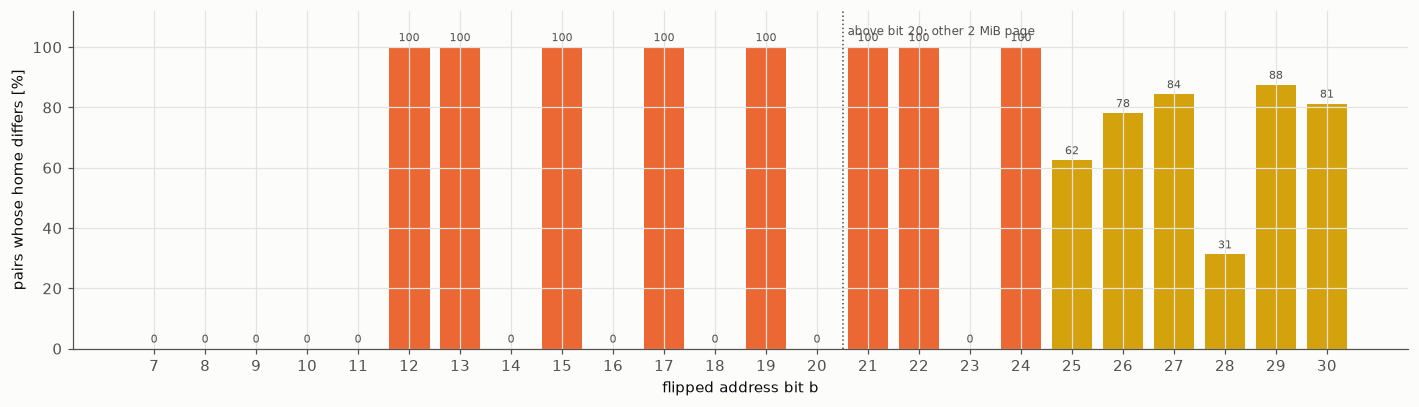

pairs per bit: 192 (32 bases × 2 directions × reps); per-direction share: max difference between the two directions 0.0 points
bits 7–20 that flip the home in every pair: [12, 13, 15, 17, 19]
XOR model of these bits: predicts 100.00 % of 17472 two-bit flips and 100.00 % of 6144 random multi-bit flips (bits 7–20)


In [8]:
hb = read_run("08__l2__hashbits.csv", RID["k2"])
frac, coef = k2_bits(hb)
lin = k2_linearity(hb, coef)
fr = hb[hb.set == "single"].groupby(["bit", "probe_smid"]).flipped_class_changed.mean().unstack()
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(7, 31)
cols = [PAL[1] if frac[b] >= 0.9 else (PAL[0] if frac[b] <= 0.1 else PAL[4]) for b in x]
ax.bar(x, 100 * frac.loc[x], color=cols)
for b in x:
    ax.text(b, 100 * frac[b] + 2, f"{100*frac[b]:.0f}", ha="center", fontsize=7.5, color=INK2)
ax.axvline(20.5, color=INK2, ls=":", lw=1); ax.text(20.6, 104, "above bit 20: other 2 MiB page", fontsize=8, color=INK2)
ax.set_xticks(x); ax.set_xlabel("flipped address bit b"); ax.set_ylabel("pairs whose home differs [%]"); ax.set_ylim(0, 112)
fig.tight_layout(); plt.show()
print(f"pairs per bit: {int(hb[hb.set=='single'].groupby('bit').size().median())} (32 bases × 2 directions × reps); "
      f"per-direction share: max difference between the two directions {100*(fr.max(axis=1)-fr.min(axis=1)).max():.1f} points")
print("bits 7–20 that flip the home in every pair:", [b for b in range(7, 21) if coef.get(b) == 1])
print(f"XOR model of these bits: predicts {100*lin['pair'][0]:.2f} % of {lin['pair'][1]} two-bit flips and "
      f"{100*lin['mask'][0]:.2f} % of {lin['mask'][1]} random multi-bit flips (bits 7–20)")

In [9]:
# First reads of every K2 line (sample 0 rows only) and the term of each 2 MiB page
f0 = k2_first_reads(RID["k2"])
PT = k2_page_terms(f0, coef)
print(f"{PT['n_lines']} lines, {PT['first_reads_per_line']} first reads each; lines with the same home in every rep and direction: "
      f"{100 * PT['lines_stable']:.2f} %")
print(f"page term g(page) = home XOR parity(in-page bits {[b for b in range(7, 21) if coef.get(b) == 1]}): identical for all "
      f"{PT['offsets_per_page']} probed offsets in {100 * PT['pages_consistent']:.1f} % of {PT['n_pages']} pages; g = 1 in {100 * PT['g1']:.1f} % of pages")
display(PT["flips"].rename_axis("page-index bit b (= virtual address bit)").T.round(1).style.format("{:.1f}")
        .set_caption(f"the {PT['n_pages']} pages of the 2 GiB buffer: pairs of pages differing in bit b whose page term differs"))


8823 lines, 6 first reads each; lines with the same home in every rep and direction: 100.00 %
page term g(page) = home XOR parity(in-page bits [12, 13, 15, 17, 19]): identical for all 4 probed offsets in 100.0 % of 1024 pages; g = 1 in 50.0 % of pages


page-index bit b (= virtual address bit),21,22,23,24,25,26,27,28,29,30
page pairs,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0,1024.0
g differs [%],100.0,100.0,0.0,100.0,65.6,65.6,84.4,34.4,78.1,78.1


In [10]:
# Sub-node class of near first reads (the ~25-cycle split) versus address bits, from the same K2 data
nr = f0[f0.line_home == f0.probe_smid.map(part_of)].copy()
thr = {}
for (r_, p_), d in nr.groupby(["rep", "probe_smid"]):
    c_, l_, _, _ = kmeans1d(d.cycles.values, None, 2)
    thr[r_, p_] = (c_[0] + c_[1]) / 2
nr["slow"] = [c > thr[r_, p_] for c, r_, p_ in zip(nr.cycles, nr.rep, nr.probe_smid)]
cls = nr.groupby(["probe_smid", "line_offset"]).slow.mean().round()
s = hb[(hb.set == "single") & (hb.flipped_class_changed == 0)]
res = {}
for b in range(7, 31):
    x = s[s.bit == b]
    v = [(cls.get((p_, o1)), cls.get((p_, o2))) for p_, o1, o2 in zip(x.probe_smid, x.base_offset, x.flipped_offset)]
    v = [(a_, b_) for a_, b_ in v if a_ is not None and b_ is not None]
    if v:
        res[b] = 100 * np.mean([a_ != b_ for a_, b_ in v])
sub = pd.Series(res, name="near lines whose sub-node class differs after flipping bit b [%]")
display(sub.round(0).to_frame().T)

,7,8,9,10,11,14,16,18,20,23,25,26,27,28,29,30
near lines whose sub-node class differs after flipping bit b [%],0.0,28.0,0.0,66.0,75.0,81.0,69.0,44.0,28.0,53.0,58.0,29.0,60.0,59.0,25.0,67.0


- **Home labels are exact.** Every one of the 8823 lines got the same home in all 3 repetitions and in both directions, and the two directions are exactly complementary: 4384 lines are far for SM 2, the other 4439 for SM 0. The home of a line does not depend on who touched it, only on its address.
- **Inside a page, the partition is the parity of five bits: 12, 13, 15, 17 and 19.**
  - The lowest participating bit is 12, so a line's home is constant within 4 KiB and changes between the two halves of every 8 KiB.
  - Bits 7–11, 14, 16, 18 and 20 never change it.
  - The XOR (parity) model of these five bits predicts the home change of all 17 472 two-bit flips and all 6144 random multi-bit flips of bits 7–20.
- **Above the page.**
  - Every 2 MiB page carries one extra term g(page): the same for all four probed offsets in each of 1024 pages, and 1 in exactly half of them.
  - In this 2 GiB buffer, pages that differ in virtual-address bit 21, 22 or 24 always have opposite g, pages that differ in bit 23 never do, and bits 25–30 invert g for 34–84 % of the page pairs (second table).
  - These shares are not hash coefficients. A virtual-address bit above 20 only selects another page of the allocation, so the shares describe where the driver placed this buffer's pages in physical memory. A share of 0 or 100 % means that every pair of pages it forms differs in an even (0 %) or an odd (100 %) number of the physical-address bits that enter the hash; an intermediate share means the pairs differ in different ways.
  - Physical addresses are not visible from user space. The next subsection therefore separates the physical page from its virtual address.
- **The sub-node of a line is not such a parity.** No single bit of 7–30 switches the sub-node group (last table): flips change it for 25–81 % of lines, except bits 7 and 9, which never do. The choice of sub-node, unlike that of the partition, is a non-linear function of the address, presumably part of the slice selection.

#### The page term on explicitly mapped physical memory

**Tables — the page term of physical pages mapped at chosen virtual addresses.** The page term g of each 2 MiB page is computed as above, from the homes of 8 fixed in-page lines: g = home ⊕ parity of in-page bits 12, 13, 15, 17, 19.
- First table: per mapping, how often all 8 lines agree on g, and whether g is the same in every repetition and direction.
- The printed lines compare each handle's g in the three mappings A1, A2, A3.
- Second table: inside each allocation (and for the 64 handles in the order they were created), the share of page pairs j, j ⊕ 2^(b−21) whose g differs.
- Last lines: g of the first page of every aligned group of 4 pages (8 MiB).


In [11]:
pv = read_run("08__l2__k2vmm_pages.csv", RID["k2vmm"])
kv = k2vmm(pv)
print(f"run_id {RID['k2vmm']}: {pv.mapping.nunique()} mappings, {len(pv)} page rows (page × rep × direction)")
cons = kv["consistency"].rename(columns={"kind": "allocation"})
cons["allocation"] = cons.allocation.map({"vmm_2MiB_handles": "64 × 2 MiB handles", "vmm_32MiB": "cuMemCreate 32 MiB",
                                          "vmm_64MiB": "cuMemCreate 64 MiB", "cudaMalloc": "cudaMalloc"})
display(cons.style.format(precision=1).set_caption("page term per mapping: line agreement and repeatability"))
gs = pv.groupby(["mapping", "page_slot"]).page_term.mean().unstack(0)
h = kv["handles"]
print(f"page term of each of the {len(h)} handles: identical in A1 and A2 for {100 * kv['agree']['A2']:.0f} % of the handles, "
      f"in A1 and A3 for {100 * kv['agree']['A3']:.0f} %; a hash of virtual-address bits 21, 22, 24 would flip it between A1 and A2 "
      f"for every handle")
print(f"same virtual slot in A1 and A2 (different handles): identical in {100 * (gs.A1 == gs.A2)[gs.A1.notna()].mean():.1f} % of the slots")
npg = cons.pages.to_dict()
fl = kv["flips"].copy()
fl.index = [f"{i.split()[0]}: {npg[i.split()[0]]} pages" + (", 64 handles in creation order" if i.startswith("A1") else "") for i in fl.index]
fl.columns = [f"bit {b}" for b in fl.columns]
display(fl.style.format("{:.0f}", na_rep="").set_caption("page pairs (j, j XOR 2^(b−21)) inside each allocation whose page term differs [%]"))
print("page term of the first page of each aligned 8 MiB group (4 pages), in order; every group follows g, ¬g, ¬g, g:")
for k, v in kv["chunks"].items():
    print(f"  {k.split()[0]:6s} {v['first_G']}   (groups following the pattern: {100 * v['pattern_ok']:.0f} %)")


run_id 2026-10-25T01:36:09.406+00:00: 10 mappings, 2688 page rows (page × rep × direction)


,allocation,MiB,pages,rows with all 8 lines agreeing [%],pages with one G in every rep and direction [%],G = 1 [%],base,base alignment [MiB]
mapping,,,,,,,,
A1,64 × 2 MiB handles,128,64,100.0,100.0,50.0,0x308000000,128
A2,64 × 2 MiB handles,128,64,100.0,100.0,50.0,0x310000000,256
A3,64 × 2 MiB handles,128,64,100.0,100.0,50.0,0x318000000,128
B32_0,cuMemCreate 32 MiB,32,16,100.0,100.0,50.0,0x302000000,32
B32_1,cuMemCreate 32 MiB,32,16,100.0,100.0,50.0,0x304000000,64
B32_2,cuMemCreate 32 MiB,32,16,100.0,100.0,50.0,0x306000000,32
B32_3,cuMemCreate 32 MiB,32,16,100.0,100.0,50.0,0x320000000,512
B64_4,cuMemCreate 64 MiB,64,32,100.0,100.0,50.0,0x324000000,64
B64_5,cuMemCreate 64 MiB,64,32,100.0,100.0,50.0,0x328000000,128


page term of each of the 64 handles: identical in A1 and A2 for 100 % of the handles, in A1 and A3 for 100 %; a hash of virtual-address bits 21, 22, 24 would flip it between A1 and A2 for every handle
same virtual slot in A1 and A2 (different handles): identical in 12.5 % of the slots


,bit 21,bit 22,bit 23,bit 24,bit 25,bit 26,bit 27
"A1: 64 pages, 64 handles in creation order",100,100,88,88,38,38,
B32_0: 16 pages,100,100,50,50,,,
B32_1: 16 pages,100,100,100,100,,,
B32_2: 16 pages,100,100,100,100,,,
B32_3: 16 pages,100,100,100,100,,,
B64_4: 32 pages,100,100,75,75,75,,
B64_5: 32 pages,100,100,100,100,0,,
C: 128 pages,100,100,81,81,56,69,31


page term of the first page of each aligned 8 MiB group (4 pages), in order; every group follows g, ¬g, ¬g, g:
  B32_0  0111   (groups following the pattern: 100 %)
  B32_1  1001   (groups following the pattern: 100 %)
  B32_2  1001   (groups following the pattern: 100 %)
  B32_3  1001   (groups following the pattern: 100 %)
  B64_4  10000110   (groups following the pattern: 100 %)
  B64_5  01100110   (groups following the pattern: 100 %)
  C      01111001100001100111100110011001   (groups following the pattern: 100 %)
  A1     1000011001100110   (groups following the pattern: 100 %)


- **The in-page hash holds on every mapping.** In all 10 mappings (2688 page rows), the 8 lines of a page always give the same g, and every page has the same g in all repetitions and directions.
- **Confirmed: the page term is a property of the physical page, not of the virtual address.**
  - Each of the 64 handles has the same g in A1, A2 and A3.
  - In A2 every handle sits at a virtual address that differs from A1 in bits 21, 22 and 24. A hash of those virtual-address bits would have inverted g for every handle; it inverted none.
  - At the same virtual slot, A1 and A2 (which hold different handles there) agree in only 12.5 % of the slots.
- **Bits 21 and 22 behave the same in every allocation.**
  - In each of the seven allocations, and for the 64 handles in creation order, pages that differ in bit 21 or in bit 22 of the page index always have opposite g.
  - Every aligned 8 MiB group of four pages follows g, ¬g, ¬g, g.
  - This is what physical-address bits 21 and 22 in the hash produce if every aligned 8 MiB of an allocation is physically contiguous and aligned, and if consecutively created 2 MiB handles are physically adjacent.
- **Bits 23 and above depend on the allocation.**
  - Bit 23 inverts g in 50, 100, 100 and 100 % of the pairs of the four 32 MiB allocations, in 75 and 100 % for the two 64 MiB allocations, and in 81 % for the 256 MiB buffer. Bit 24 gives the same shares in each of these allocations.
  - In the 2 GiB buffer above, bit 23 never inverted g and bit 24 always did.
  - No single choice of "in the hash / not in the hash" for virtual bits 23 and 24 fits all allocations. Above 8 MiB, the allocations differ in how their 8 MiB groups lie in physical memory.
- **Confirmed, inferred, open.**
  - Confirmed: a line's home depends only on its physical location: the parity of in-page bits 12, 13, 15, 17, 19, combined with a term of its physical 2 MiB page.
  - Inferred: physical-address bits 21 and 22 enter the hash. This fits every allocation tested, but rests on the assumption of physically contiguous, aligned 8 MiB groups.
  - Open: which physical bits from 23 upward enter the hash. Bit 24 can neither be confirmed nor excluded, because physical addresses are not readable.


### 4. Copies: who reads what, and what a write does (K3)

**Figure 5 — the life of a line in three SMs.**
- A writes 32 lines: 16 homed in A's partition (orange), 16 in B's (blue).
- Then, in order: B reads each line 64 times, C (B's partition, another GPC) does the same, then A; then A rewrites the lines and B reads them again.
- Median over lines and 5 repetitions, p5–p95 shaded; each phase is its own kernel launch. The three triples cross the partition boundary; the fourth, the control triple (all three SMs in partition 0), is in the table only.

K3 run_id 2026-10-25T01:36:10.640+00:00: triples A 0 B 2 C 6 (cross), A 2 B 8 C 0 (cross), A 14 B 126 C 12 (cross), A 0 B 8 C 10 (control)


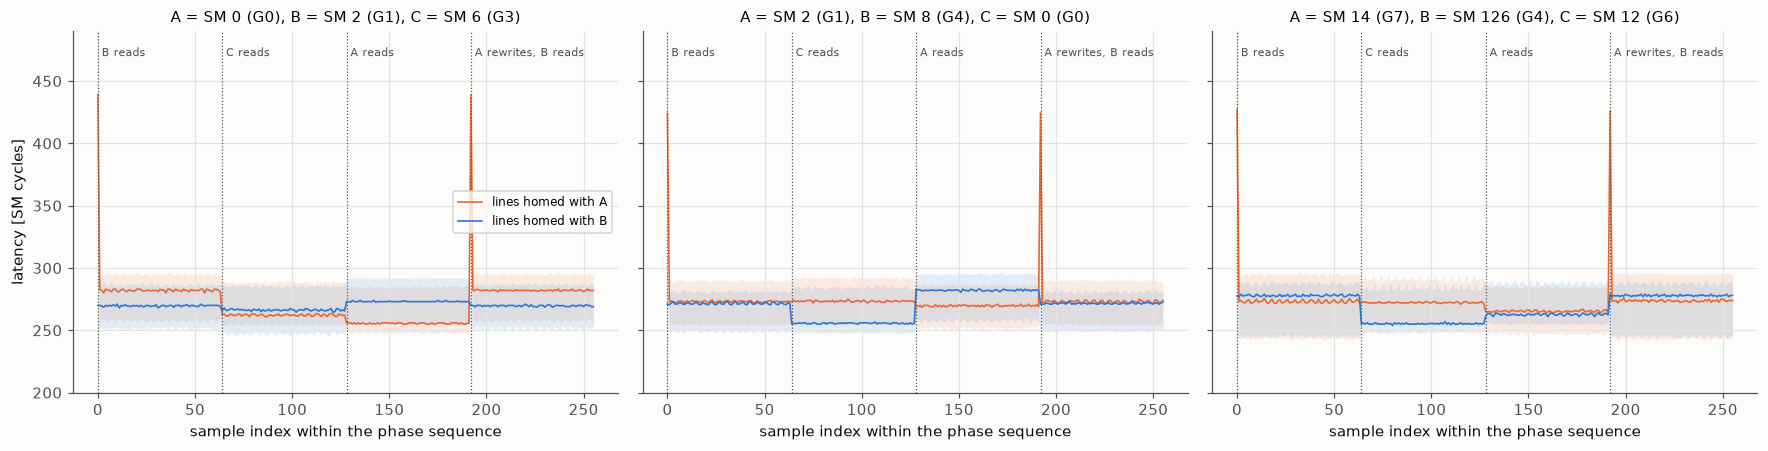

In [12]:
k3 = read_run("08__l2__probe.csv", RID["k3"])
k3 = k3[k3.kernel == "K3"].copy()
k3["cyc"] = k3.cycles - TP
repl = read_run("08__l2__replication_v2.csv", RID["k3"])
kinds = repl.groupby(["a_smid", "b_smid", "c_smid"], sort=False).triple_kind.first()
print(f"K3 run_id {RID['k3']}: triples " + ", ".join(f"A {a} B {b} C {c} ({k})" for (a, b, c), k in kinds.items()))
PH = ["b_read", "c_read", "a_read", "b_read_after_a_write"]
PHL = ["B reads", "C reads", "A reads", "A rewrites, B reads"]
PG = sig.groupby("gpc").partition.first()
apart = lambda a: int(PG[GPC[a]])
cross_t = [list(t) for t, k in kinds.items() if k == "cross"]
same_t = [list(t) for t, k in kinds.items() if k == "control"]
assert all(apart(a) != apart(b) for a, b, _ in cross_t) and all(len({apart(x) for x in t}) == 1 for t in same_t)
fig, axs = plt.subplots(1, len(cross_t), figsize=(5.4 * len(cross_t), 4.2), sharey=True, squeeze=False)
for ax, (A, B, C) in zip(axs[0], cross_t):
    d = k3[(k3.first_touch_smid == A) & (k3.seq_mode == "launch") & (((k3.probe_smid == B) & k3.phase.isin(["b_read", "b_read_after_a_write"]))
                                                                   | ((k3.probe_smid == C) & (k3.phase == "c_read")) | ((k3.probe_smid == A) & (k3.phase == "a_read")))]
    d = d.assign(x=d.phase.map({p: i for i, p in enumerate(PH)}) * 64 + d.sample_idx,
                 hm=np.where(d.line_home == apart(A), "lines homed with A", "lines homed with B"))
    for c, h in zip([PAL[1], PAL[0]], ["lines homed with A", "lines homed with B"]):
        g = d[d.hm == h].groupby("x").cyc
        ax.plot(g.median().index, g.median(), "-", lw=1.1, color=c, label=h)
        ax.fill_between(g.median().index, g.quantile(.05), g.quantile(.95), color=c, alpha=0.12, lw=0)
    for i, l in enumerate(PHL):
        ax.axvline(64 * i, color=INK2, ls=":", lw=0.8); ax.text(64 * i + 2, 470, l, fontsize=7.5, color=INK2)
    ax.set_title(f"A = SM {A} (G{GPC[A]}), B = SM {B} (G{GPC[B]}), C = SM {C} (G{GPC[C]})", fontsize=9.5)
    ax.set_xlabel("sample index within the phase sequence"); ax.set_ylim(200, 490)
axs[0][0].set_ylabel("latency [SM cycles]"); axs[0][0].legend(fontsize=8, loc="center right")
fig.tight_layout(); plt.show()

In [13]:
r = repl.copy()
r["triple"] = [f"A {a} G{GPC[a]} · B {b} G{GPC[b]} · C {c} G{GPC[c]}" + (" (control)" if k == "control" else "")
               for a, b, c, k in zip(r.a_smid, r.b_smid, r.c_smid, r.triple_kind)]
# cross triples: A and B in different partitions; control triple: A, B, C all in A's partition
r["home"] = np.where(r.line_home == r.a_smid.map(apart), np.where(r.triple_kind == "control", "homed with A and B", "homed with A"),
                     np.where(r.triple_kind == "control", "homed in the other partition", "homed with B"))
r["cyc"] = r.median_cycles - TP
PHS = ["b_first", "b_repeat", "c_first", "a_after_first", "b_after_a_write_first", "b_after_a_write_repeat"]
t = r[r.phase.isin(PHS)].pivot_table(index=["triple", "home"], columns=["phase"], values="cyc", aggfunc="median")[PHS]
display(t.round(0).style.format("{:.0f}").set_caption("per-line values (sample 0 = *_first, median of samples 1–63 = *_repeat), median over lines and reps, both sequencings; cycles"))
lf = r[r.phase.isin(PHS) & (r.triple_kind == "cross")].pivot_table(index=["seq_mode"], columns=["home", "phase"], values="cyc", aggfunc="median")
display(lf.round(0).style.format("{:.0f}").set_caption("launch-sequenced vs flag-sequenced (the three cross-partition triples)"))
# one value check per line, phase and configuration (the *_first row; the *_repeat row repeats the same check)
ok = r[r.phase == "b_after_a_write_first"]
ok0 = r[r.phase == "b_first"]
print(f"B read the value A wrote last in {100*ok.qword1_ok.mean():.1f} % of {len(ok)} checks after the rewrite "
      f"({100*ok[ok.triple_kind == 'cross'].qword1_ok.mean():.1f} % of the {(ok.triple_kind == 'cross').sum()} in the cross-partition triples), "
      f"and the earlier value in {100*ok0.qword1_ok.mean():.1f} % of {len(ok0)} checks before it")
fl = r[(r.seq_mode == "flag") & (r.phase == "b_after_a_write_first")]
gap = (fl.phase_t0_ns - r[(r.seq_mode == "flag") & (r.phase == "a_after_first")].phase_t1_ns.values[:len(fl)]) / 1e3
print(f"flag mode: B's last phase started {np.median(gap):.1f} µs (median) after A's read phase ended (A's rewrite in between)")

B read the value A wrote last in 100.0 % of 1280 checks after the rewrite (100.0 % of the 960 in the cross-partition triples), and the earlier value in 100.0 % of 1280 checks before it
flag mode: B's last phase started 1.8 µs (median) after A's read phase ended (A's rewrite in between)


- **B's first read of A's lines is far (424–439 cycles), the next 63 are near (274–281):** B's read created a copy in B's partition.
- **C finds the copy.** C's first read of the same lines is near (262–273 cycles), although C never read them and sits in another GPC and another sub-node: **a copy serves the whole partition**, not just the SM that caused it.
- **A rewriting a line removes the copy.** After A's rewrite, B's first read is far again (424–439) and returns the new value in 100 % of the 960 value checks of the cross-partition triples (1280 checks including the control triple).
  - The write updates the line's home and invalidates the copy in the other partition. Stale data was never observed.
  - When the line is homed in B's partition, A's write goes there and B's reads stay near.
- **Launch boundaries change nothing.** The same sequence ordered by release/acquire flags inside one kernel launch gives the same values within 2 cycles (second table). The copies are not an artefact of kernel boundaries.
- **The control triple inside one partition never sees a far access** (all its values 256–275 cycles). Its lines are homed either in the triple's own partition or in the other one; the latter are near for all three SMs once A's write has left a copy.

### 5. How much one SM can keep (K4)

**Figure 6 — one SM chasing a growing footprint.** A random chain over all lines of the footprint, after the L2 was emptied and the lines written either by the probe SM or alternately by SM 0 and SM 2.
- (a): latency per hop for the first and the third timed pass, and for an untimed fourth pass (whole-pass time / hops); median over SMs 0 and 2 and 3 repetitions.
- (b), (c): every timed access sorted into four latency classes: near hit, far hit, and a lower and an upper latency class of HBM misses.
- (d): how the latency classes are defined. A Gaussian mixture of four components is fitted by expectation-maximisation to the exact histogram of all accesses of the third pass (all footprints, both touch patterns, both SMs, all repetitions). All footprints are needed: from 38 MiB on there are no near hits. The class boundaries lie where neighbouring components have equal posterior probability (table below).

K4 run_id 2026-10-24T21:42:20.004+00:00


,mean,SD,weight [%],upper boundary
near hit,271.2,13.4,11.3,343.8
far hit,429.1,15.5,20.2,466.1
"HBM miss, lower latency class",505.2,14.8,37.0,541.7
"HBM miss, upper latency class",681.4,99.0,31.5,


EM from 50 random starts (seed 0): 14 reached the best log-likelihood (-5.9098 per sample); class boundaries 343.8, 466.1, 541.7 cycles


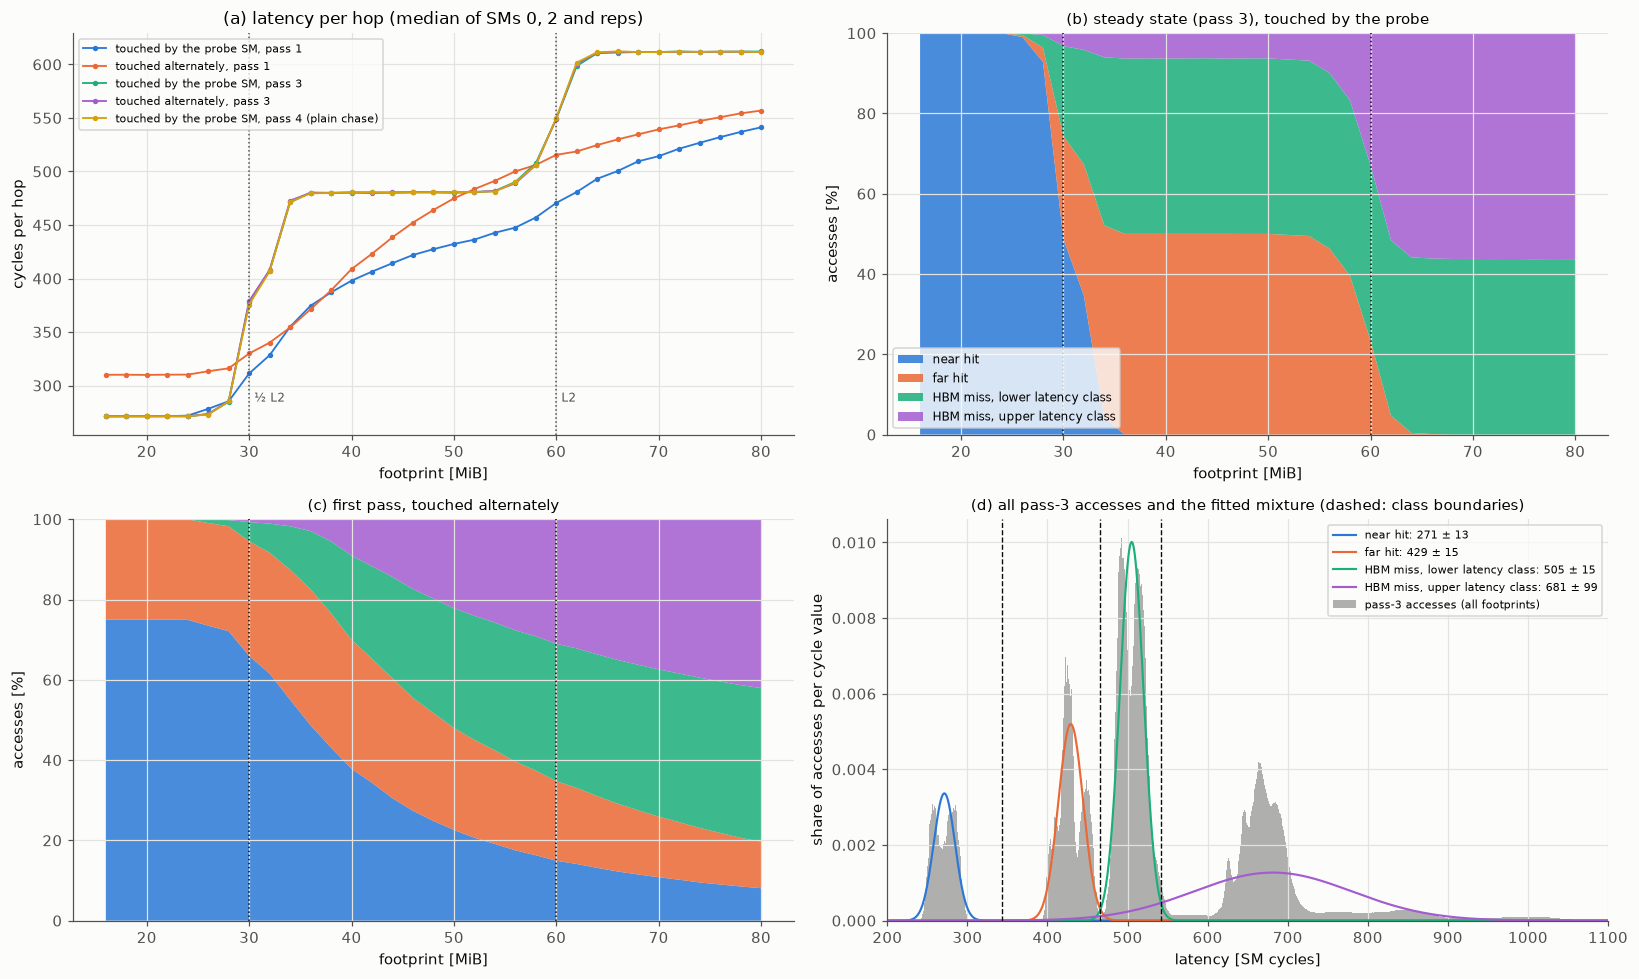

In [14]:
cap = read_run("08__l2__capacity.csv", RID["k4"])
ch = read_run("08__l2__capacity_hist.csv", RID["k4"])
ch["cyc"] = ch.cycles - TP
print(f"K4 run_id {RID['k4']}")
# Latency classes: 4-component Gaussian mixture (EM on the exact (value, count) histogram) of every timed access of pass 3
# (pass index 2), all footprints 16–80 MiB, both touch patterns, SMs 0 and 2, all reps. Footprints ≥ 38 MiB alone contain no
# near hits, so all footprints are needed to populate the four classes. Boundaries at equal posterior.
h2 = ch[ch["pass"] == 2].groupby("cyc")["count"].sum()
GM = gmm1d(h2.index.values, h2.values, k=4, n_starts=50, seed=0)
edges = BND = GM["boundaries"]
names = ["near hit", "far hit", "HBM miss, lower latency class", "HBM miss, upper latency class"]
display(pd.DataFrame({"mean": GM["mean"], "SD": GM["sd"], "weight [%]": 100 * GM["weight"],
                      "upper boundary": list(edges) + [np.nan]}, index=names).round(1).style.format(precision=1, na_rep="")
        .set_caption(f"Gaussian mixture of {int(h2.sum()):,} pass-3 accesses (cycles, timer pair removed)"))
print(f"EM from 50 random starts (seed 0): {GM['starts_at_best']} reached the best log-likelihood ({GM['loglik']:.4f} per sample); "
      f"class boundaries {', '.join(f'{e:.1f}' for e in edges)} cycles")
ch["cls"] = np.searchsorted(edges, ch.cyc.values)
fr = ch.groupby(["touch_pattern", "footprint_bytes", "pass", "cls"])["count"].sum().unstack(fill_value=0)
fr = fr.div(fr.sum(axis=1), axis=0)
cur = cap.groupby(["touch_pattern", "pass", "footprint_bytes"]).cycles_per_hop.median()
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
ax = axs[0, 0]
for c, (pat, ps, lab) in zip(PAL, [("probe", 0, "touched by the probe SM, pass 1"), ("alternate", 0, "touched alternately, pass 1"),
                                   ("probe", 2, "touched by the probe SM, pass 3"), ("alternate", 2, "touched alternately, pass 3"),
                                   ("probe", 3, "touched by the probe SM, pass 4 (plain chase)")]):
    y = cur[pat, ps]
    ax.plot(y.index / 2**20, y.values, "-o", ms=2.5, lw=1.2, color=c, label=lab)
for xv, l in [(30, "½ L2"), (60, "L2")]:
    ax.axvline(xv, color=INK2, ls=":", lw=1); ax.text(xv + 0.5, 285, l, fontsize=8, color=INK2)
ax.set_xlabel("footprint [MiB]"); ax.set_ylabel("cycles per hop"); ax.legend(fontsize=7.5); ax.set_title("(a) latency per hop (median of SMs 0, 2 and reps)")
for ax, (pat, ps, tt) in zip([axs[0, 1], axs[1, 0]], [("probe", 2, "(b) steady state (pass 3), touched by the probe"),
                                                    ("alternate", 0, "(c) first pass, touched alternately")]):
    d = fr.xs((pat, ps), level=("touch_pattern", "pass"))
    ax.stackplot(d.index / 2**20, *[100 * d.get(k, 0) for k in range(4)], labels=names, colors=[PAL[0], PAL[1], PAL[2], PAL[3]], alpha=0.85)
    for xv in (30, 60):
        ax.axvline(xv, color=INK, ls=":", lw=1)
    ax.set_xlabel("footprint [MiB]"); ax.set_ylabel("accesses [%]"); ax.set_ylim(0, 100); ax.set_title(tt, fontsize=10)
axs[0, 1].legend(fontsize=8, loc="lower left")
ax = axs[1, 1]
from scipy.stats import norm
xs = np.arange(200, 1101)
ax.bar(h2.index, h2.values / h2.sum(), width=1.0, color=INK2, alpha=0.45, lw=0, label="pass-3 accesses (all footprints)")
for k in range(4):
    ax.plot(xs, GM["weight"][k] * norm.pdf(xs, GM["mean"][k], GM["sd"][k]), color=PAL[k], lw=1.4, label=f"{names[k]}: {GM['mean'][k]:.0f} ± {GM['sd'][k]:.0f}")
for e in edges:
    ax.axvline(e, color=INK, ls="--", lw=0.9)
ax.set_xlim(200, 1100); ax.set_xlabel("latency [SM cycles]"); ax.set_ylabel("share of accesses per cycle value")
ax.set_title("(d) all pass-3 accesses and the fitted mixture (dashed: class boundaries)", fontsize=10); ax.legend(fontsize=7.5)
fig.tight_layout(); plt.show()


In [15]:
tab = fr.xs(2, level="pass").unstack("touch_pattern")
sel = [F for F in sorted(cap.footprint_bytes.unique()) if (F >> 20) % 8 == 0 or (F >> 20) in (26, 30, 34, 38)]
show = pd.DataFrame({f"{names[k]} [%], {pat}": 100 * tab[(k, pat)] for k in range(4) for pat in ("probe", "alternate") if (k, pat) in tab})
show.index = show.index // 2**20
display(show.loc[[F >> 20 for F in sel]].round(1).style.format("{:.1f}").set_caption("steady state (pass 3): latency classes of the accesses vs footprint [MiB]"))
nc = NCU["capacity"].copy()
nc["MiB"] = nc.lines.astype(float) * 128 / 2**20
hops = nc.lines.astype(float)
nt = pd.DataFrame({"footprint MiB": nc.MiB, "SM": nc.probe_smid, "touch": nc.what, "cycles/hop": nc.first_median,
                   "L2 lookup hits / hop": nc["lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum"] / hops,
                   "L2 lookup misses / hop": nc["lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum"] / hops,
                   "partition-link sectors / hop": nc["lts__t_sectors_srcunit_ltcfabric.sum"] / hops,
                   "HBM bytes / hop": nc["dram__bytes_read.sum"] / hops})
display(nt[nt.SM == 0].set_index(["footprint MiB", "touch"]).drop(columns="SM").round(2).style.format(precision=2)
        .set_caption("profiled plain chase of SM 0 after two warm passes"))

,"near hit [%], probe","near hit [%], alternate","far hit [%], probe","far hit [%], alternate","HBM miss, lower latency class [%], probe","HBM miss, lower latency class [%], alternate","HBM miss, upper latency class [%], probe","HBM miss, upper latency class [%], alternate"
footprint_bytes,,,,,,,,
16,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
24,100.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0
26,99.0,98.9,0.5,0.6,0.4,0.5,0.1,0.1
30,48.7,48.6,25.6,25.7,22.4,22.5,3.2,3.2
32,34.6,33.0,32.7,33.5,28.5,29.2,4.2,4.2
34,4.1,3.8,47.9,48.1,41.9,42.0,6.0,6.1
38,0.0,0.0,50.0,50.0,43.7,43.7,6.3,6.3
40,0.0,0.0,50.0,50.0,43.7,43.7,6.3,6.3
48,0.0,0.0,50.0,50.0,43.7,43.7,6.3,6.3


**What one SM can keep in L2 (steady state, panel b and the first table).**

| footprint | what the chase sees |
|---|---|
| ≤ 26 MiB | 100 % near hits, 271 cycles per hop |
| 30–34 MiB | near hits disappear quickly |
| 38–52 MiB | exactly **50 % far hits** and 50 % HBM misses (43.7 % in the lower, 6.3 % in the upper latency class); ≈ 480 cycles per hop |
| ≥ 64 MiB | no hits: 43.7 % of the misses in the lower latency class (centre 505 cycles), 56.3 % in the upper one (centre 681, with a slow tail to ≈ 1100); 612 cycles per hop |

**Interpretation.**
- **Up to ≈ 26–30 MiB: everything fits in the reader's partition.** Every line the SM reads ends up in its own partition, at home or as a copy, and one partition holds 30 MiB.
- **Between 30 and 60 MiB: the far half still hits at home.** The reader's partition must hold its own half of the lines plus copies of the other half, more than it can hold, so a cyclic chase misses there every time. The half homed in the other partition still fits there: reads of those lines are far hits. The lines homed in the reader's own partition go to HBM.
- **Beyond ≈ 60 MiB:** the far half no longer fits at home either, and everything comes from HBM.

**Latency classes.** These classes sort accesses by latency, not by home. The homes of the chased lines are split exactly 50/50 between the partitions (section 3), and misses to lines homed in the reader's partition that take longer than usual also fall into the upper class. The 43.7 / 56.3 % split of the misses is therefore not a split into near-homed and far-homed lines. The mixture places the near and far hits at 271 and 429 cycles (SD 13 and 15), the lower latency class of the HBM misses at 505 (SD 15) and the upper one at 681 cycles. The upper class is a narrow peak near 670 cycles followed by a slow tail up to ≈ 1050 cycles, which one Gaussian cannot follow: its component is wide (SD 99, panel d). This wide component puts the boundary between the two miss classes at 542 cycles, on the upper flank of the lower class's peak rather than in the flat density minimum between ≈ 550 and 600 cycles; 1.4 % of the accesses at ≥ 64 MiB lie between 542 and 600 cycles and count as upper class. The near hit / far hit boundary (344 cycles) lies in an empty gap; the far hit / HBM boundary (466) lies in a narrow dip.

**Other observations.**
- **The touch pattern matters only for the first pass.** Lines written alternately by SMs of both partitions leave a quarter of the first reads far even at 16 MiB. From the second pass on, both patterns are identical.
- **The counters agree.** Below 24 MiB there is one L2 hit per hop. At 36–48 MiB there are 2 lookup misses (one 64-byte request to the reader's partition) and exactly 1 partition-link sector per hop, with ≈ 34 B of HBM reads per hop: half the hops miss to HBM. From 64 MiB every hop reads 64 B from HBM.

### 6. Hardware counters

Nsight Compute, application replay (each counter pass re-runs the binary with the full protocol), clock lock kept:
1. one line read 64 times per profiled kernel, 32 lines, from SM 2 and from SM 0 (lines written by SM 0);
2. L1 hits of 32 lines × 64 reads with `.cg` and `.ca`;
3. SM 2 reading every line of a 16 MiB buffer that SM 0 wrote (≈ 65 500 far-homed and 65 500 near-homed lines), once per line: first reads of the far-homed lines, first reads of the near-homed lines, then a second read of the far-homed lines.
   - Both line lists are read once beforehand, so the profiled kernel's list reads hit in the L2.
   - Every profiled kernel is profiled alone, in its own run of the binary, with one L2 counter. On this toolkit any two L2 counters need four replay passes; one L2 counter, HBM bytes and the kernel duration fit into a single pass.
   - Baseline: the same 132-block launch in which every block exits at once, profiled the same way; it is subtracted.
   - Each probed line also costs one read of its page's reserved line (the address-translation warm-up) and a quarter sector of each of the two lists. These hit in the L2 and appear among the lookup hits.

In [16]:
nl = NCU["lines"].copy()
one = nl[nl.what == "line"].copy()
one["class"] = np.where(one.first_median.astype(float) - TP > BND[0], "far first read", "near first read")  # near/far boundary of section 5
cols = {"lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum": "lookup hits", "lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum": "lookup misses",
        "lts__t_sectors_srcunit_tex_op_read_lookup_hit.max": "hits in the busiest slice", "lts__t_sectors_srcunit_tex_op_read_lookup_miss.max": "misses in the busiest slice",
        "lts__t_sectors_srcunit_ltcfabric.sum": "partition-link sectors", "l1tex__t_sectors_pipe_lsu_mem_global_op_ld_lookup_hit.sum": "L1 hits"}
cols = {k: v for k, v in cols.items() if k in one}
display(one.groupby(["probe_smid", "class"])[list(cols)].median().rename(columns=cols).round(1)
        .assign(lines=one.groupby(["probe_smid", "class"]).size()).style.format(precision=1)
        .set_caption("one line, 64 reads (+1 TLB-warm read, 2 list reads), per profiled kernel: median over lines"))
l1 = nl[nl.what.str.startswith("l1_")].set_index("what")
print("32 lines × 64 reads from SM 0: L1 hits " + ", ".join(f"{w}: {int(l1.loc[w, 'l1tex__t_sectors_pipe_lsu_mem_global_op_ld_lookup_hit.sum'])}" for w in l1.index)
      + f" of {int(l1['l1tex__t_sectors_pipe_lsu_mem_global_op_ld.sum'].iloc[0])} global-load sectors")
for t in ("lines", "capacity"):
    x = NCU[t][NCU[t].first_median.astype(float) > 0]
    print(f"ncu {t} (multi-pass profile): {int(x.pass_runs.iloc[0])} binary runs; profiled-kernel cycles in the first run / median of the others: "
          f"{(x.first_median_pass1.astype(float) / x.first_median.astype(float)).median():.2f}×")
print(f"L2 slices reported by the profiler: {int(nl['device__attribute_l2s_count'].iloc[0])}; counter passes per profiled kernel: "
      f"{int(nl['profiler__replayer_passes'].iloc[0])}")
per, raw, FAB_RIDS = fabric1()
npass = int(raw.filter(like="passes").max().max())
print(f"\nfirst-read counter test: {len(FAB_RIDS)} binary runs, each profiling one kernel with one counter ({npass} pass): run_ids "
      f"{FAB_RIDS[0]} … {FAB_RIDS[-1]}")
base = raw.loc["all_exit"]
print("all-exit baseline (same 132-block grid, every block exits): " + ", ".join(
    f"{c} {base[c]:.0f}" for c in ["L2 lookup misses", "L2 lookup hits", "partition-link sectors"]) +
      f"; HBM bytes {base.filter(like='HBM').min():.0f}–{base.filter(like='HBM').max():.0f}; duration {base.filter(like='duration').median() / 1e3:.1f} µs")
per["median first read in the profiled kernel [cycles, raw]"] -= TP
per = per.rename(columns={"median first read in the profiled kernel [cycles, raw]": "median first read in the profiled kernel [cycles]",
                          "HBM bytes (min–max of the 3 runs)": "HBM bytes (min–max over the 3 runs)"})
display(per.rename(index={"far_first": "far-homed lines, first read", "near_first": "near-homed lines, first read",
                          "far_second": "far-homed lines, second read"})
        .style.format({c: "{:.3f}" for c in ["L2 lookup misses", "L2 lookup hits", "partition-link sectors"]} |
                      {"kernel time per line [ns]": "{:.0f}", "median first read in the profiled kernel [cycles]": "{:.0f}"})
        .set_caption("SM 2 reads every line of a 16 MiB buffer written by SM 0, once: counters per line, all-exit baseline subtracted"))
old = NCU["fabric"].set_index("what")
print(f"superseded profile (run {old.run_id.iloc[0]}: lists not warmed, all kernels in one 4-pass application replay): lookup misses per line "
      + ", ".join(f"{w} {(old.loc[w, 'lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum'] - old.loc['empty', 'lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum']) / old.loc[w, 'lines']:.2f}"
                  for w in ("far_first", "near_first", "far_second"))
      + f"; link sectors far − near first read {(old.loc['far_first', 'lts__t_sectors_srcunit_ltcfabric.sum'] - old.loc['near_first', 'lts__t_sectors_srcunit_ltcfabric.sum']) / old.loc['far_first', 'lines']:.2f} per line")


32 lines × 64 reads from SM 0: L1 hits l1_cg: 48, l1_ca: 2064 of 2144 global-load sectors
ncu lines (multi-pass profile): 4 binary runs; profiled-kernel cycles in the first run / median of the others: 2.59×
ncu capacity (multi-pass profile): 4 binary runs; profiled-kernel cycles in the first run / median of the others: 2.76×
L2 slices reported by the profiler: 96; counter passes per profiled kernel: 4

first-read counter test: 12 binary runs, each profiling one kernel with one counter (1 pass): run_ids 2026-10-25T01:36:12.715+00:00 … 2026-10-25T01:36:48.135+00:00
all-exit baseline (same 132-block grid, every block exits): L2 lookup misses 0, L2 lookup hits 0, partition-link sectors 1458; HBM bytes 6400–6656; duration 2.1 µs


,L2 lookup misses,L2 lookup hits,partition-link sectors,HBM bytes (min–max over the 3 runs),kernel time per line [ns],median first read in the profiled kernel [cycles],lines
"far-homed lines, first read",2.000,1.501,2.061,4.5–5.8,655,429,65533
"near-homed lines, first read",0.021,2.491,0.064,2.7–3.9,558,270,65531
"far-homed lines, second read",0.013,2.488,0.085,1.7–4.3,561,276,65533


superseded profile (run 2026-10-24T21:46:32.761+00:00: lists not warmed, all kernels in one 4-pass application replay): lookup misses per line far_first 2.50, near_first 0.50, far_second 0.00; link sectors far − near first read 2.00 per line


- **A far first read is one 64-byte request: 2 sectors looked up in the reader's partition, 2 sectors over the partition link** (second table).
  - Far-homed lines, first read: 2.000 lookup misses per line and 2.06 partition-link sectors.
  - Near-homed lines, first read: no miss and 2.49 lookup hits per line = 1 for the line + 1 for the page's warm-up line + 0.5 for the two lists. A near hit is a single-sector lookup.
  - Second read of the far-homed lines: the same 2.49 hits and no miss. The copy left by the first read serves it, also as a single-sector lookup.
  - The far first reads show 1.50 hits per line: the warm-up line and the lists, without the line itself.
- **What remains in the counters is background.**
  - Near reads and second reads still show 0.06–0.09 link sectors per line, and the far first reads 0.06 above 2.
  - This is ≈ 90–150 sectors per millisecond of kernel time in all three kernels (they run 37–43 ms). The 2 µs baseline cannot capture traffic that grows with kernel duration.
  - HBM reads of 2–6 bytes per line vary between runs of the same kernel: no line is fetched from HBM.
- **The single-pass profile does not slow the kernel.** The profiled kernels' median first reads (429, 270 and 276 cycles) equal the unprofiled latencies. The far first reads take 97 ns longer per line than the near ones, which is the 159-cycle latency difference at 1635 MHz.
- **These numbers replace an earlier profile.** That profile ran all four kernels in one four-pass application replay without warming the lists. Its far first reads showed 2.50 lookup misses per line and its near first reads 0.50: the extra half sector per line came from the list reads missing after the L2 was emptied. Its difference in link sectors between far and near first reads, 2.00 per line, agrees with the new profile.
- **Each line is served by one slice.**
  - The profiler reports 96 L2 slices.
  - Its CSV export contains no per-slice values for these counters on this toolkit, so the slice that serves a given line cannot be identified here.
  - The `.max` roll-up of the first table shows that all 63–64 repeated reads of a line hit a single slice. That profile did not warm the lists, so list misses (at most 2 sectors per slice) hide where the far line's own 2 miss sectors are looked up.
- **`.cg` loads never hit in L1.** The 48 L1 hits come from reading the line list; `.ca` adds exactly 32 × 63 = 2016 L1 hits.
- **Anomaly: the first counter pass of a multi-pass profile runs slow.** In both four-pass profiles (one line, capacity) the first pass ran the profiled kernels 2.59× and 2.76× slower than the other three; the superseded first-read profile showed the same (2.60×). Cycle counts of these profiles are therefore taken from passes 2–4, and counts are used as exported. Profiled alone in a single pass, the first-read kernels run at normal speed (above).

## Insights

**1. Placement in the L2 is a 2 × 2 grid, and the costs add up.** SM cycles at the locked 1635 MHz, timer pair removed, first reads of lines that exist only at home:

| line relative to the reading SM | median | p5–p95 |
|---|---|---|
| same partition, same sub-node | **251** (154 ns) | 240–265 |
| same partition, other sub-node | **280** (172 ns) | 265–297 |
| other partition, partner sub-node | **417** (256 ns) | 385–435 |
| other partition, other sub-node | **443** (272 ns) | 418–464 |

- Partition 0 = {G0, G4, G5, G6}, partition 1 = {G1, G2, G3, G7}.
- Sub-nodes {G0, G6}, {G4, G5} | {G1, G2}, {G3, G7}; partners {G0, G6} ↔ {G3, G7} and {G4, G5} ↔ {G1, G2}.
- Crossing the partition boundary costs **+162 cycles** and crossing between the two sub-node rows **+29**, independently of each other.
- The sub-node split is far outside chance: its first component carries 95–96 % of the SM × line variance, against at most 5.5 % in 1000 permutations without SM × line structure.
- On top of this, every SM has its own offset (−8 to +10 cycles around its GPC's median), shared by the two SMs of a TPC and the same for every line. It is a position term on the SM side.
- Labels for all 132 SMs are in the experiment's per-SM map.

**2. Homes are fixed by the physical address, and copies make far hits rare.**
- The partition of a line is the parity of in-page physical address bits 12, 13, 15, 17 and 19, combined with a term of its physical 2 MiB page. The page term follows the physical page wherever it is mapped. Bits 21 and 22 invert it in every allocation tested, so physical bits 21 and 22 very likely belong to the hash; the higher bits cannot be resolved from user space.
- Lines alternate between the partitions every 4 KiB, and any buffer is split exactly in half.
- Which SM touches a line first does not move its home.
- Any read or write of a line leaves a copy in the accessor's partition, and that copy:
  - serves every SM of the partition;
  - sits in the same sub-node row as the line's home;
  - is invalidated when the line is written from the other side, so readers never see stale data.
- Consequently, an SM pays the far latency at most once per line and partition, unless a write from the other partition intervenes. Data shared by both halves of the chip is held twice.

**3. Effective capacity for one reader is 30 MiB at near latency, and 60 MiB in total.**
- A single SM keeps everything at near latency only up to the size of one partition (≈ 30 MiB; the chase stays flat to 26 MiB).
- Between 30 and 60 MiB, half of its accesses become far hits served by the other partition, and the other half miss to HBM, even though the data would fit in the L2 once.
- Data placed so that it is read only from its home partition keeps the full 60 MiB at near latency.

**4. A far first read moves 64 B over the partition link; hits are single sectors.** A far first read is a 2-sector request that misses in the reader's partition and crosses the link. A near hit, and a hit on a copy, is a single-sector lookup with no link traffic. The cost of sharing data across partitions is paid on first use and on every write.

**Limitations.**
- Physical addresses are not visible from user space. The page term was shown to belong to the physical page; that bits 21 and 22 of the physical address produce it is inferred from the layout of the allocations (aligned 8 MiB groups contiguous). Bits from 23 upward behave differently in different allocations and remain unresolved.
- The sub-node choice of a line is not a parity of address bits, and per-slice counter values are not exported by the profiler on this toolkit. The slice-level mapping remains open, together with the ≈ 390-cycle far mode and the per-SM position term.
- The split of the HBM misses into a lower and an upper latency class (43.7 / 56.3 % at ≥ 64 MiB) is a split by latency, not by home, and depends on the class model. A Gaussian mixture describes the hit classes and the lower miss class well, but not the upper miss class with its slow tail; its boundary at 542 cycles counts 1.4 % of the accesses that a boundary in the density minimum would put in the lower class.
- The first-read counters contain ≈ 0.06–0.09 sectors per line of background link traffic that grows with kernel duration and is not removed by the baseline.
- All latencies are for one thread on an otherwise idle GPU.
